Adapted Code From : 

* https://github.com/NielsRogge/Transformers-Tutorials/blob/master/TrOCR/Fine_tune_TrOCR_on_IAM_Handwriting_Database_using_native_PyTorch.ipynb
* https://github.com/NielsRogge/Transformers-Tutorials/blob/master/TrOCR/Fine_tune_TrOCR_on_IAM_Handwriting_Database_using_Seq2SeqTrainer.ipynb
* https://github.com/spmallick/learnopencv/tree/master/TrOCR-Getting-Started-with-Transformer-Based-OCR

In [38]:
!pip install -q transformers datasets jiwer evaluate peft bitsandbytes
!pip install --upgrade huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.7/69.7 MB 25.5 MB/s eta 0:00:00:00:0100:01


In [12]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()

from huggingface_hub import login
access_token = user_secrets.get_secret("HF_Token")
login=login(token=access_token)

# LoRAlize Model

In [14]:
from transformers import TrOCRProcessor, VisionEncoderDecoderModel, AutoTokenizer
from peft import LoraConfig, get_peft_model

# For example, using a TrOCR model pre-trained on handwritten text:
model_name = "ds1219/Pandithaya-TrOCR-Sinhala-Printed"
processor = TrOCRProcessor.from_pretrained(model_name)
# (Optionally, if you want to change the decoder tokenizer—for example, to a RoBERTa tokenizer for a different language—you can load it separately)
tokenizer = AutoTokenizer.from_pretrained("ds1219/Pandithaya-TrOCR-Sinhala-Printed")

# If you want to swap in a different tokenizer for the decoder, assign it to the processor:
processor.tokenizer = tokenizer

# Load the pre-trained TrOCR model:
model = VisionEncoderDecoderModel.from_pretrained(model_name)

preprocessor_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.22k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/485k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/988k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.75k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.26G [00:00<?, ?B/s]

Config of the encoder: <class 'transformers.models.vit.modeling_vit.ViTModel'> is overwritten by shared encoder config: ViTConfig {
  "attention_probs_dropout_prob": 0.0,
  "encoder_stride": 16,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 768,
  "image_size": 384,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "model_type": "vit",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 16,
  "qkv_bias": false,
  "transformers_version": "4.47.0"
}

Config of the decoder: <class 'transformers.models.trocr.modeling_trocr.TrOCRForCausalLM'> is overwritten by shared decoder config: TrOCRConfig {
  "activation_dropout": 0.0,
  "activation_function": "gelu",
  "add_cross_attention": true,
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "classifier_dropout": 0.0,
  "cross_attention_hidden_size": 768,
  "d_model": 1024,
  "decoder_attention_heads": 16,
  "decoder_ffn_dim": 4096,
  "decoder

generation_config.json:   0%|          | 0.00/273 [00:00<?, ?B/s]

In [15]:
model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
model.config.vocab_size = model.config.decoder.vocab_size

In [55]:
dora_config = LoraConfig(
    r=8,
    lora_alpha=32,
    lora_dropout=0.05,
    use_dora=True,
    target_modules=["query", "value"], # or try ["key", "query", "value"]
)

lora_config = LoraConfig(
    r=8,
    lora_alpha=32,
    lora_dropout=0.1,
    bias="none",
    target_modules=["q_proj", "v_proj"]  # Adjust these names if needed (check your model's module names)
)

In [56]:
model.encoder = get_peft_model(model.encoder, dora_config)
model.decoder = get_peft_model(model.decoder, lora_config)

In [58]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable params: {trainable_params} / Total params: {total_params}")

Trainable params: 1075200 / Total params: 316293632


## Prepare data

We first download the data. Here, I'm just using the IAM test set, as this was released by the TrOCR authors in the unilm repository. It can be downloaded from [this page](https://github.com/microsoft/unilm/tree/master/trocr). 

Let's make a [regular PyTorch dataset](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html). We first create a Pandas dataframe with 2 columns. Each row consists of the file name of an image, and the corresponding text.

In [4]:
import pandas as pd

def import_dataset(path):
  df = pd.read_csv(path, sep='\t', usecols=[0,1], names=['file_name', 'text'])
  #df = pd.read_csv(path, sep='\t', usecols=[0,1])
  #df.rename(columns={'file': 'file_name', 'labels': 'text'}, inplace=True)
  return(df)

In [5]:
train_df = import_dataset('/kaggle/input/synthetic-word-small/train.tsv')
train_df = train_df.truncate(after=20000)
train_df.head()

,file_name,text
0,0_0.jpg,අභිමන්
1,0_1.jpg,දැහැණ
2,1_0.jpg,ඇන්තනී
3,2_0.jpg,නවීනභාවය
4,3_0.jpg,තොරතුරැ


In [6]:
test_df = import_dataset("/kaggle/input/synthetic-word-small/test.tsv")
test_df = test_df.truncate(after=4000)
test_df.head()

,file_name,text
0,0_0.jpg,ද්‍රවශීළ
1,2_0.jpg,බිස්කටි
2,1_0.jpg,පැල්මඩුල්ලටත්
3,3_0.jpg,ගුණාගුණ
4,0_1.jpg,ආදාරකය


We split up the data into training + testing, using sklearn's `train_test_split` function.

Each element of the dataset should return 2 things:
* `pixel_values`, which serve as input to the model.
* `labels`, which are the `input_ids` of the corresponding text in the image.

We use `TrOCRProcessor` to prepare the data for the model. `TrOCRProcessor` is actually just a wrapper around a `ViTFeatureExtractor` (which can be used to resize + normalize images) and a `RobertaTokenizer` (which can be used to encode and decode text into/from `input_ids`). 

In [7]:
import torch
from torch.utils.data import Dataset
from PIL import Image

class IAMDataset(Dataset):
    def __init__(self, root_dir, df, processor, max_target_length=128):
        self.root_dir = root_dir
        self.df = df
        self.processor = processor
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # get file name + text
        file_name = self.df['file_name'][idx]
        if ".jpg" not in file_name:
          file_name = (file_name.split(".")[0]) + ".jpg"
        text = self.df['text'][idx]

        if text != "":
            # prepare image (i.e. resize + normalize)
            image = Image.open(self.root_dir + file_name).convert("RGB")
            pixel_values = self.processor(image, return_tensors="pt").pixel_values
            # add labels (input_ids) by encoding the text
            labels = self.processor.tokenizer(text,
                                              padding="max_length",
                                              max_length=self.max_target_length).input_ids
            # important: make sure that PAD tokens are ignored by the loss function
            labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]
    
            encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
            return encoding

Let's initialize the training and evaluation datasets:

In [8]:
from transformers import TrOCRProcessor

processor = TrOCRProcessor.from_pretrained("ds1219/Pandithaya-TrOCR-Sinhala-Printed")
train_dataset = IAMDataset(root_dir='/kaggle/input/synthetic-word-small/train/',
                           df=train_df,
                           processor=processor)
eval_dataset = IAMDataset(root_dir='/kaggle/input/synthetic-word-small/test/',
                           df=test_df,
                           processor=processor)

preprocessor_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.22k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/485k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/988k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/695 [00:00<?, ?B/s]

In [8]:
print("Number of training examples:", len(train_dataset))
print("Number of validation examples:", len(eval_dataset))

Number of training examples: 20001
Number of validation examples: 4001


Let's verify an example from the training dataset:

In [9]:
encoding = train_dataset[0]
for k,v in encoding.items():
  print(k, v.shape)

pixel_values torch.Size([3, 384, 384])
labels torch.Size([128])


We can also check the original image and decode the labels:

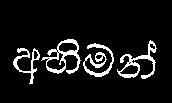

In [10]:
image = Image.open(train_dataset.root_dir + train_df['file_name'][0]).convert("RGB")
image

In [11]:
labels = encoding['labels']
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.decode(labels, skip_special_tokens=True)
print(label_str)

අභිමන්


Let's create corresponding dataloaders:

In [12]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(train_dataset, batch_size=4, shuffle=True)
eval_dataloader = DataLoader(eval_dataset, batch_size=4)

## Train a model

Here, we initialize the TrOCR model from its pretrained weights. Note that the weights of the language modeling head are already initialized from pre-training, as the model was already trained to generate text during its pre-training stage. Refer to the paper for details.

In [12]:
from transformers import VisionEncoderDecoderModel
import torch

#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# for GPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# for TPU
#device = xm.xla_device()
#torch.set_default_tensor_type('torch.FloatTensor')

model = VisionEncoderDecoderModel.from_pretrained("ds1219/Pandithaya-TrOCR-Sinhala-Printed")
model.to(device)

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-stage1 and are newly initialized: ['encoder.pooler.dense.weight', 'encoder.pooler.dense.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): PatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0): ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=False)
              (key): Linear(in_features=768, out_features=768, bias=False)
              (value): Linear(in_features=768, out_features=768, bias=False)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=768, 

Importantly, we need to set a couple of attributes, namely:
* the attributes required for creating the `decoder_input_ids` from the `labels` (the model will automatically create the `decoder_input_ids` by shifting the `labels` one position to the right and prepending the `decoder_start_token_id`, as well as replacing ids which are -100 by the pad_token_id)
* the vocabulary size of the model (for the language modeling head on top of the decoder)
* beam-search related parameters which are used when generating text.

In [13]:
# set special tokens used for creating the decoder_input_ids from the labels
model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
# make sure vocab size is set correctly
model.config.vocab_size = model.config.decoder.vocab_size

# set beam search parameters
model.config.eos_token_id = processor.tokenizer.sep_token_id
model.config.max_length = 64
model.config.early_stopping = True
model.config.no_repeat_ngram_size = 3
model.config.length_penalty = 2.0
model.config.num_beams = 4

In [ ]:
EPOCHS = 1

We will evaluate the model on the Character Error Rate (CER), which is available in HuggingFace Datasets (see [here](https://huggingface.co/metrics/cer)).

In [14]:
from datasets import load_metric

cer_metric = load_metric("cer")

In [27]:
def compute_cer(pred_ids, label_ids):
    pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(label_ids, skip_special_tokens=True)

    cer = cer_metric.compute(predictions=pred_str, references=label_str)

    return cer

In [28]:
from transformers import AdamW
from tqdm.notebook import tqdm

optimizer = AdamW(model.parameters(), lr=5e-5)

for epoch in range(EPOCHS):  # loop over the dataset multiple times
   # train
   model.train()
   train_loss = 0.0
   for batch in tqdm(train_dataloader):
      # get the inputs
      for k,v in batch.items():
        batch[k] = v.to(device)

      # forward + backward + optimize
      outputs = model(**batch)
      loss = outputs.loss
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()

      train_loss += loss.item()

   print(f"Loss after epoch {epoch}:", train_loss/len(train_dataloader))
    
   # evaluate
   model.eval()
   valid_cer = 0.0
   with torch.no_grad():
     for batch in tqdm(eval_dataloader):
       # run batch generation
       outputs = model.generate(batch["pixel_values"].to(device))
       # compute metrics
       cer = compute_cer(pred_ids=outputs, label_ids=batch["labels"])
       valid_cer += cer 

   print("Validation CER:", valid_cer / len(eval_dataloader))

model.save_pretrained(".")

  0%|          | 0/146 [00:00<?, ?it/s]

Validation CER: 0.5624370839885325


  0%|          | 0/146 [00:00<?, ?it/s]

KeyboardInterrupt: ignored

## Inference

Note that after training, you can easily load the model using the .`from_pretrained(output_dir)` method.

For inference on new images, I refer to my inference notebook, that can also be found in my [Transformers Tutorials repository](https://github.com/NielsRogge/Transformers-Tutorials) on Github.